# MARITIME-X · 02 Results analysis

Reads the analytical results that the Spark pipeline wrote to MongoDB (compact, already aggregated). Every figure here is a view of computed results; nothing is typed in.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pymongo import MongoClient
db = MongoClient('mongodb://localhost:27017')['maritime_x']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
PRUSSIAN, MARINE, TEAL, AMBER, RED = '#003153', '#005B8F', '#2F8F8B', '#C88A27', '#B94A48'

## Port congestion (PCI, project-defined)

In [2]:
ports = pd.DataFrame(list(db.ports.find({'pci': {'$ne': None}}, {'_id': 0})))
cols = ['port_name', 'pci', 'pci_band', 'arrivals', 'avg_queue', 'avg_waiting_h', 'avg_dwell_h', 'avg_turnaround_h', 'utilization']
ports.sort_values('pci', ascending=False)[cols].head(12).round(2)

,port_name,pci,pci_band,arrivals,avg_queue,avg_waiting_h,avg_dwell_h,avg_turnaround_h,utilization
0,New Orleans (Mississippi River),84.3,Severe,88,22.65,5.82,35.37,56.75,0.81
1,Houston,83.4,Severe,258,51.27,3.64,41.63,52.49,0.90
2,Port Arthur / Sabine Pass,70.9,High,54,12.14,7.13,38.14,51.02,0.75
3,Baton Rouge / South Louisiana,67.1,High,51,8.54,7.27,27.25,37.60,0.87
4,Los Angeles / Long Beach,65.6,High,81,10.04,4.57,42.49,49.78,0.84
5,Vancouver,63.9,High,46,15.77,2.24,36.38,39.56,0.87
6,Oakland / San Francisco Bay,60.6,High,33,9.83,6.16,32.16,48.15,0.75
7,Freeport,60.3,High,36,4.72,9.81,33.99,42.14,0.75
8,Honolulu,41.6,Moderate,11,0.92,6.21,26.84,35.99,0.71
9,Beaumont,39.0,Moderate,33,0.44,1.71,41.91,46.12,0.83


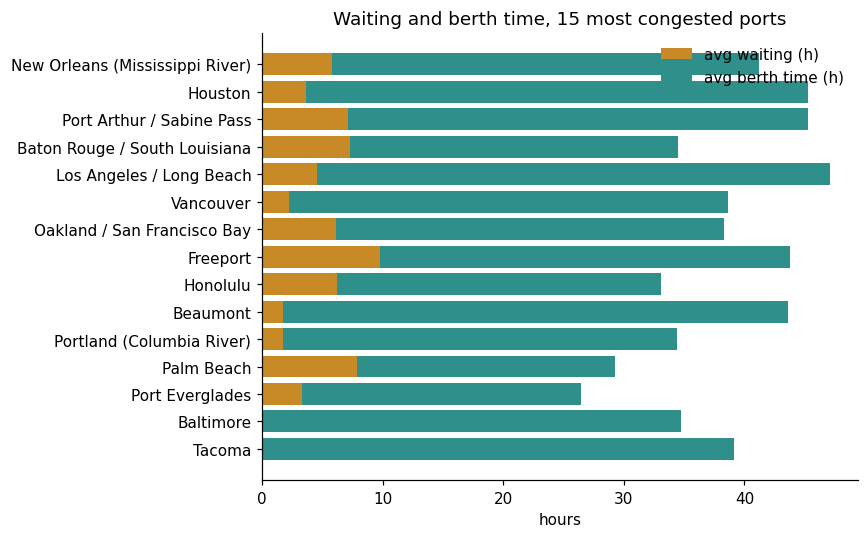

In [3]:
top = ports.sort_values('pci').tail(15)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.port_name, top.avg_waiting_h, color=AMBER, label='avg waiting (h)')
ax.barh(top.port_name, top.avg_dwell_h, left=top.avg_waiting_h, color=TEAL, label='avg berth time (h)')
ax.set_xlabel('hours'); ax.set_title('Waiting and berth time, 15 most congested ports'); ax.legend(frameon=False)
plt.tight_layout()

## Turnaround

In [4]:
v = pd.DataFrame(list(db.port_visits.find({'visit_type': 'BERTHED', 'complete': True}, {'_id': 0, 'turnaround_h': 1, 'waiting_h': 1, 'dwell_h': 1, 'vessel_group': 1})))
print(len(v), 'complete berthed visits')
v.groupby('vessel_group')[['waiting_h', 'dwell_h', 'turnaround_h']].describe().round(1).T

766 complete berthed visits


vessel_group        Cargo  Tanker
waiting_h    count  521.0   245.0
             mean     1.3     3.5
             std      6.8    11.5
             min      0.0     0.0
             25%      0.0     0.0
             50%      0.0     0.0
             75%      0.0     0.0
             max     90.2    84.7
dwell_h      count  521.0   245.0
             mean    28.0    34.4
             std     24.1    21.5
             min      0.5     0.6
             25%     11.3    19.6
             50%     21.3    34.7
             75%     37.4    47.6
             max    131.2   107.1
turnaround_h count  521.0   245.0
             mean    33.4    43.1
             std     25.8    26.2
             min      0.6     0.6
             25%     15.7    24.3
             50%     26.9    41.7
             75%     44.0    60.4
             max    134.1   123.8

## AIS gap anomaly scores

risk_level
Normal           20551
Watch            25528
Suspicious        2631
High Priority       62
Name: count, dtype: int64


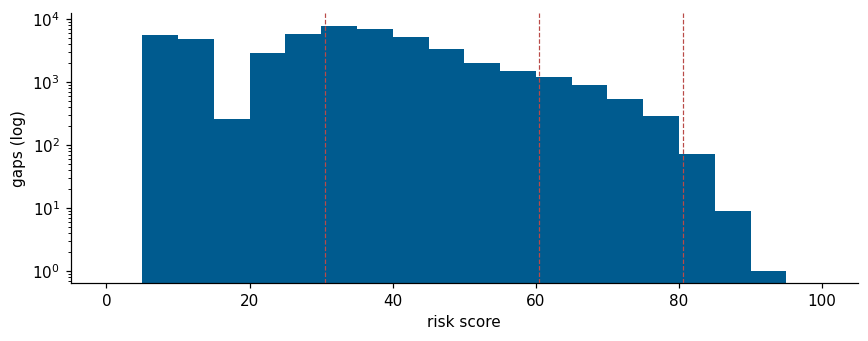

In [5]:
g = pd.DataFrame(list(db.anomalies.find({}, {'_id': 0, 'risk_score': 1, 'risk_level': 1, 'gap_h': 1, 'transceiver': 1, 'vessel_group': 1, 'start_dist_to_port_nm': 1})))
print(g.risk_level.value_counts().reindex(['Normal', 'Watch', 'Suspicious', 'High Priority']))
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(g.risk_score, bins=range(0, 101, 5), color=MARINE, log=True)
for x in (30, 60, 80): ax.axvline(x + .5, color=RED, lw=.8, ls='--')
ax.set_xlabel('risk score'); ax.set_ylabel('gaps (log)'); plt.tight_layout()

In [6]:
el = g[g.risk_score > 60]
print(f'elevated gaps: {len(el)}; share starting > 10 nm from a monitored port: {(el.start_dist_to_port_nm > 10).mean():.0%}')
pd.crosstab(el.vessel_group, el.transceiver).assign(total=lambda d: d.sum(axis=1)).sort_values('total', ascending=False).head(10)

elevated gaps: 2693; share starting > 10 nm from a monitored port: 84%


transceiver,A,B,total
vessel_group,,,
Pleasure Craft,92,540,632
Passenger,491,65,556
Cargo,331,0,331
Sailing,7,270,277
Fishing,77,134,211
Towing,169,19,188
Tanker,145,0,145
Other,94,12,106
Tug,71,7,78


## AIS proximity / visibility events

Observation only: the data contains AIS position reports, not radio messages.

In [7]:
vis = pd.DataFrame(list(db.ais_visibility.find({}, {'_id': 0, 'visibility': 1, 'risk_level': 1, 'neighbours_total': 1, 'neighbours_near_during': 1})))
pd.crosstab(vis.visibility, vis.risk_level, margins=True)

risk_level,High Priority,Suspicious,All
visibility,,,
coverage_observed,59,2365,2424
coverage_unconfirmed,0,49,49
isolated,3,217,220
All,62,2631,2693


## MLlib KMeans gap clusters

In [8]:
m = db.ml_model.find_one({}, {'_id': 0})
print('k =', m['k'], '| silhouette by k:', {k: round(s, 3) for k, s in m['silhouette_by_k'].items()})
pd.DataFrame(list(db.cluster_profiles.find({}, {'_id': 0, 'cluster': 1, 'size': 1, 'share': 1, 'avg_ml_score': 1, 'description': 1}))).round(3)

k = 4 | silhouette by k: {'4': 0.323, '5': 0.303, '6': 0.298, '7': 0.292, '8': 0.283}


,avg_ml_score,cluster,description,share,size
0,33.99,3,"high local traffic density, low distance from ...",0.396,19330
1,77.22,0,"high implied vs reported speed mismatch, high ...",0.056,2745
2,36.14,2,"high distance from port, low local traffic den...",0.391,19083
3,51.61,1,"high distance across gap, high implied speed, ...",0.156,7614


## Potential MMSI identity inconsistency

In [9]:
pd.DataFrame(list(db.identity_vessels.find({'flagged': True}, {'_id': 0, 'mmsi': 1, 'vessel_group': 1, 'conflict_events': 1, 'isolated_outliers': 1, 'max_implied_kn': 1}).sort('conflict_events', -1).limit(10)))

,mmsi,vessel_group,conflict_events,isolated_outliers,max_implied_kn
0,360000000,Other,2009,422,296505.7
1,374158000,Cargo,1977,158,126268.1
2,200000000,Towing,1973,676,477849.4
3,338393461,Pleasure Craft,872,452,54655.3
4,366688000,Pleasure Craft,859,392,22526.2
5,316027782,Pleasure Craft,761,393,3593.6
6,303295000,Towing,388,240,2095451.6
7,300000000,Other,210,70,29595.8
8,538006053,Tanker,201,229,94419.7
9,366744930,Fishing,182,180,120045.2
